# TC5061 — Notebook Baseline: Flujo básico de un proyecto de Machine Learning

**Alumna:** Lizeth Ruiz · **Matrícula:** A01840361

**Dataset:** *IBM HR Analytics Employee Attrition & Performance* (Kaggle), un dataset ficticio creado por científicos de datos de IBM.
Fuente: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

**Problema:** clasificación binaria. Hay que predecir si un empleado **dejará la empresa** (`Attrition = Yes`) a partir de sus características demográficas, laborales y de satisfacción.


> **Nota:** este notebook se conserva **solo para la exploración de datos** (EDA y diagnóstico de calidad). La carga, el preprocesamiento, el entrenamiento y la evaluación se migraron a `train.py`, que registra cada corrida en MLflow.

In [1]:
# Instalación de dependencias
import importlib.util, subprocess, sys
faltantes = [pkg for pkg in ["seaborn"] if importlib.util.find_spec(pkg) is None]
if faltantes:
    pip_names = ["scikit-learn" if p == "sklearn" else p for p in faltantes]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pip_names])
    print("Instalado:", pip_names, "-> si es Colab, reinicia la sesión y vuelve a correr desde aquí.")
else:
    print("Todas las dependencias están instaladas.")

Todas las dependencias están instaladas.


In [2]:
# Librerías estándar y de análisis de datos
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Semilla global para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Estilo de las gráficas
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

print("pandas:", pd.__version__)

pandas: 3.0.6


## Paso 1. Carga y descripción del dataset

In [3]:
# Ruta del archivo CSV (carpeta data/)
DATA_PATH = "data/WA_Fn-UseC_-HR-Employee-Attrition.csv"

# Lectura del archivo. 'utf-8-sig' elimina el BOM que trae la primera columna ("\ufeffAge")
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# Dimensiones del dataset: (registros, variables)
print(f"Registros: {df_raw.shape[0]}  |  Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 1470  |  Variables: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [4]:
# Tipo de dato, número de no nulos y memoria de cada columna
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [5]:
# Resumen de la estructura: tipo, valores únicos y un ejemplo de cada variable
estructura = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "valores_unicos": df_raw.nunique(),
    "nulos": df_raw.isna().sum(),
    "ejemplo": df_raw.iloc[0],
})
estructura

,tipo,valores_unicos,nulos,ejemplo
Age,int64,43,0,41
Attrition,str,2,0,Yes
BusinessTravel,str,3,0,Travel_Rarely
DailyRate,int64,886,0,1102
Department,str,3,0,Sales
DistanceFromHome,int64,29,0,1
Education,int64,5,0,2
EducationField,str,6,0,Life Sciences
EmployeeCount,int64,1,0,1
EmployeeNumber,int64,1470,0,1


### Diccionario de variables

El dataset tiene **1,470 registros (empleados)** y **35 variables**: 26 numéricas enteras y 9 de texto (categóricas). Cada fila es un empleado.

| Grupo | Variables | Significado |
|---|---|---|
| **Objetivo** | `Attrition` | Si el empleado dejó la empresa (`Yes`/`No`) |
| Demográficas | `Age`, `Gender`, `MaritalStatus`, `DistanceFromHome` | Edad, género, estado civil y distancia de casa al trabajo (km) |
| Educación | `Education` (1=Below College … 5=Doctor), `EducationField` | Nivel educativo (ordinal) y área de estudio |
| Puesto | `Department`, `JobRole`, `JobLevel` (1–5), `BusinessTravel`, `OverTime` | Departamento, rol, nivel jerárquico, frecuencia de viajes y si hace horas extra |
| Compensación | `MonthlyIncome`, `DailyRate`, `HourlyRate`, `MonthlyRate`, `PercentSalaryHike`, `StockOptionLevel` (0–3) | Ingreso mensual, tarifas, % de aumento y nivel de opciones de acciones |
| Trayectoria | `TotalWorkingYears`, `NumCompaniesWorked`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager`, `TrainingTimesLastYear` | Antigüedad total, en la empresa, en el rol, desde el último ascenso, con el jefe actual y capacitaciones del último año |
| Satisfacción (1=Low … 4=Very High) | `EnvironmentSatisfaction`, `JobSatisfaction`, `RelationshipSatisfaction`, `JobInvolvement`, `WorkLifeBalance` | Encuestas internas en escala ordinal |
| Desempeño | `PerformanceRating` (1–4) | Calificación de desempeño |
| Administrativas | `EmployeeCount`, `EmployeeNumber`, `Over18`, `StandardHours` | Contador, ID del empleado, mayor de edad y horas estándar |

**Observación inicial:** varias variables numéricas (`Education`, `JobLevel`, las de satisfacción) son en realidad **categorías ordinales codificadas como enteros**. Esto se revisa en la limpieza.

## Paso 2. Análisis exploratorio (EDA)

### 2.1 Variable objetivo

,conteo,proporcion
Attrition,,
No,1233,0.839
Yes,237,0.161


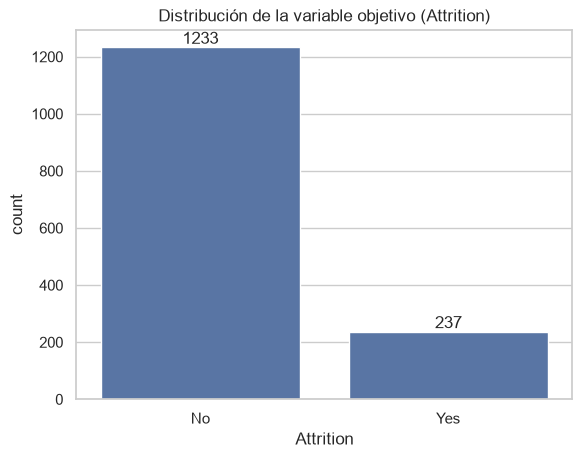

In [6]:
# Conteo y proporción de la variable objetivo
conteo = df_raw["Attrition"].value_counts()
proporcion = df_raw["Attrition"].value_counts(normalize=True).round(3)
display(pd.DataFrame({"conteo": conteo, "proporcion": proporcion}))

# Gráfica de barras de la clase objetivo
ax = sns.countplot(data=df_raw, x="Attrition", order=["No", "Yes"])
ax.bar_label(ax.containers[0])
ax.set_title("Distribución de la variable objetivo (Attrition)")
plt.show()

**Hallazgo:** el dataset está **desbalanceado**. Solo ~16% de los empleados se fue (237 de 1,470). Por eso la *accuracy* sola es engañosa: un modelo que siempre prediga "No" tendría ~84% de accuracy sin aprender nada. En la evaluación se usarán también *recall*, *F1* y *ROC-AUC*.

### 2.2 Estadísticas descriptivas

In [7]:
# Estadísticas descriptivas de las variables numéricas (transpuestas para leerlas mejor)
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


In [8]:
# Estadísticas de las variables categóricas: valores únicos, moda y su frecuencia
df_raw.describe(exclude="number").T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


**Hallazgos:**
- `EmployeeCount` (siempre 1), `StandardHours` (siempre 80) y `Over18` (siempre "Y") son **constantes**. No aportan información.
- `EmployeeNumber` es un **identificador**, no una característica del empleado.
- `MonthlyIncome` va de ~1,000 a ~20,000 con media > mediana, lo que indica **sesgo a la derecha**.
- Las escalas son muy distintas (por ejemplo `DailyRate` en cientos y `MonthlyRate` en miles), así que conviene **estandarizar** antes de un modelo lineal.

### 2.3 Distribución de variables numéricas

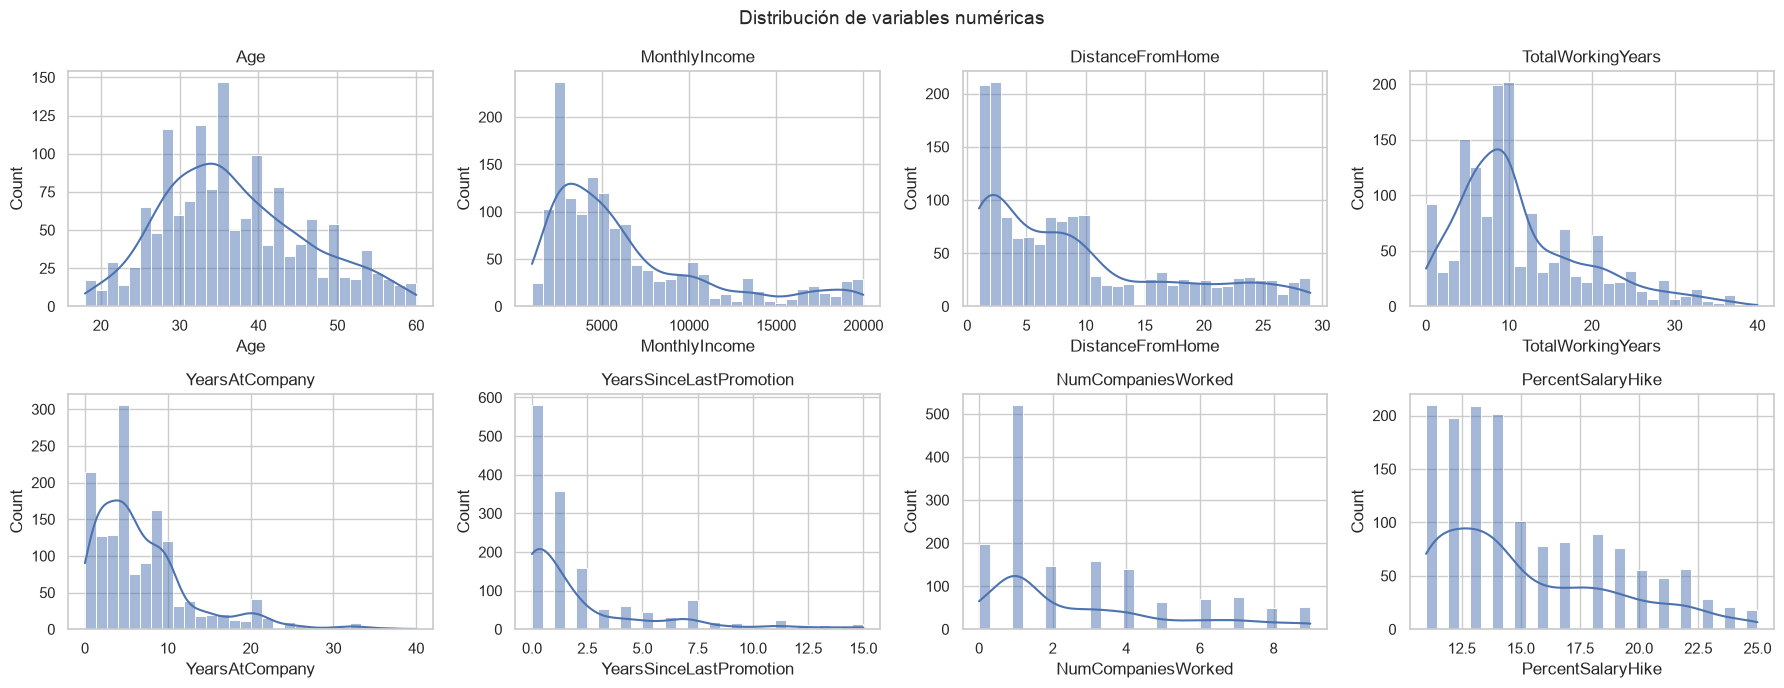

In [9]:
# Variables numéricas continuas o de rango amplio más relevantes
num_clave = ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears",
             "YearsAtCompany", "YearsSinceLastPromotion", "NumCompaniesWorked", "PercentSalaryHike"]

# Histogramas con densidad (KDE) en una cuadrícula de 2x4
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_clave):
    sns.histplot(df_raw[col], kde=True, ax=ax, bins=30)
    ax.set_title(col)
plt.suptitle("Distribución de variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

**Hallazgo:** `Age` es casi normal (centrada en ~36 años). `MonthlyIncome`, `TotalWorkingYears`, `YearsAtCompany` y `YearsSinceLastPromotion` tienen **cola larga a la derecha**: pocos empleados con muchos años o ingresos altos.

### 2.4 Relación de las variables con la salida (Attrition)

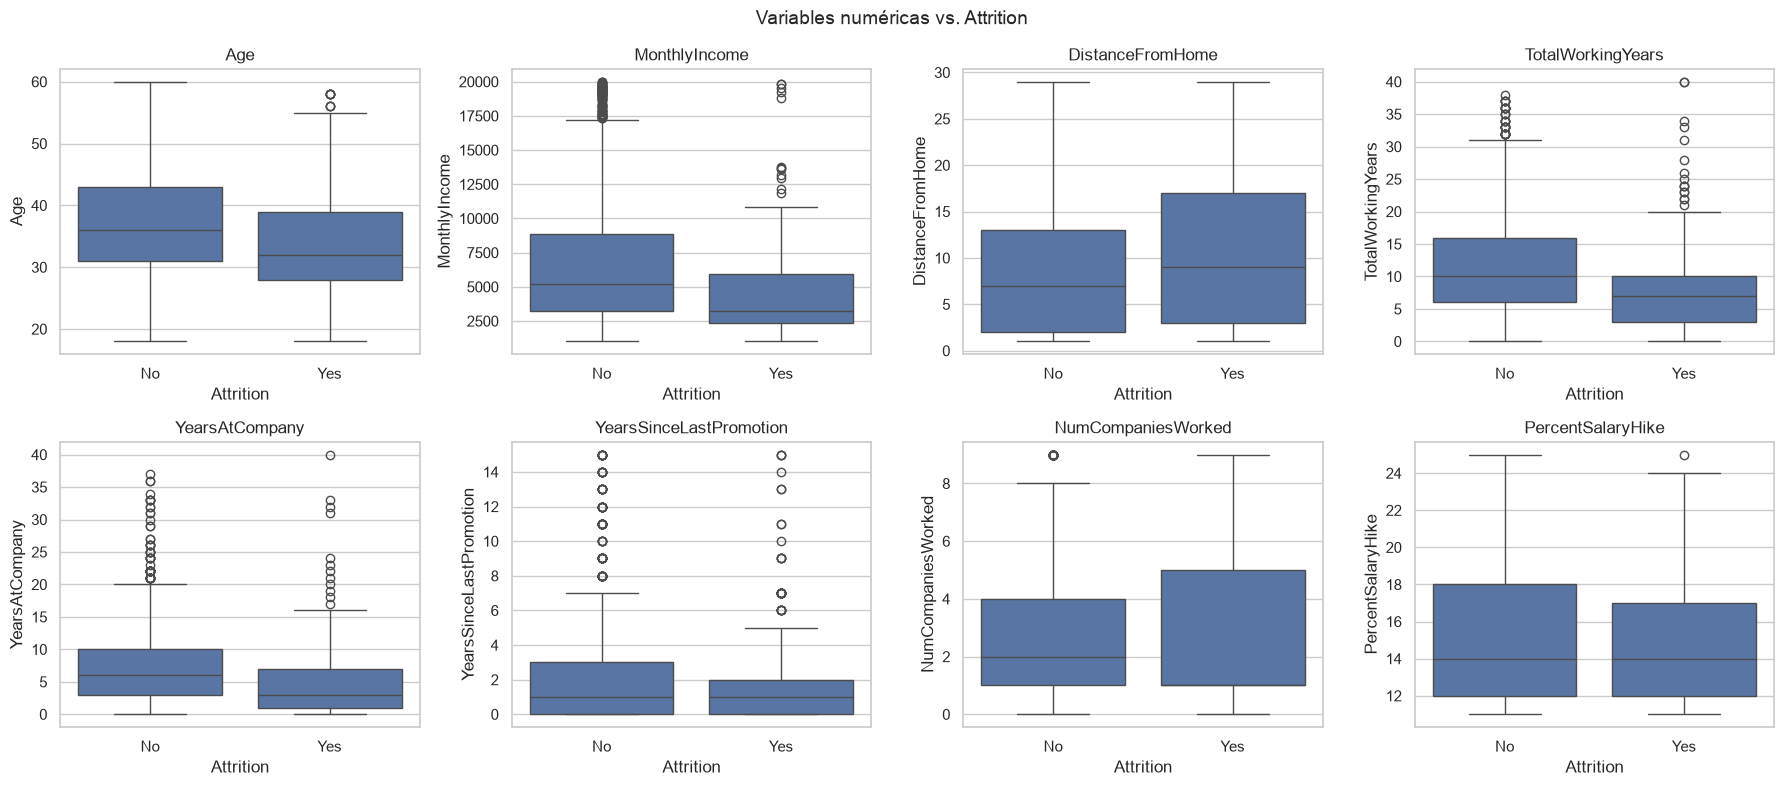

In [10]:
# Boxplots de variables numéricas separadas por clase objetivo
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_clave):
    sns.boxplot(data=df_raw, x="Attrition", y=col, ax=ax, order=["No", "Yes"])
    ax.set_title(col)
plt.suptitle("Variables numéricas vs. Attrition", fontsize=14)
plt.tight_layout()
plt.show()

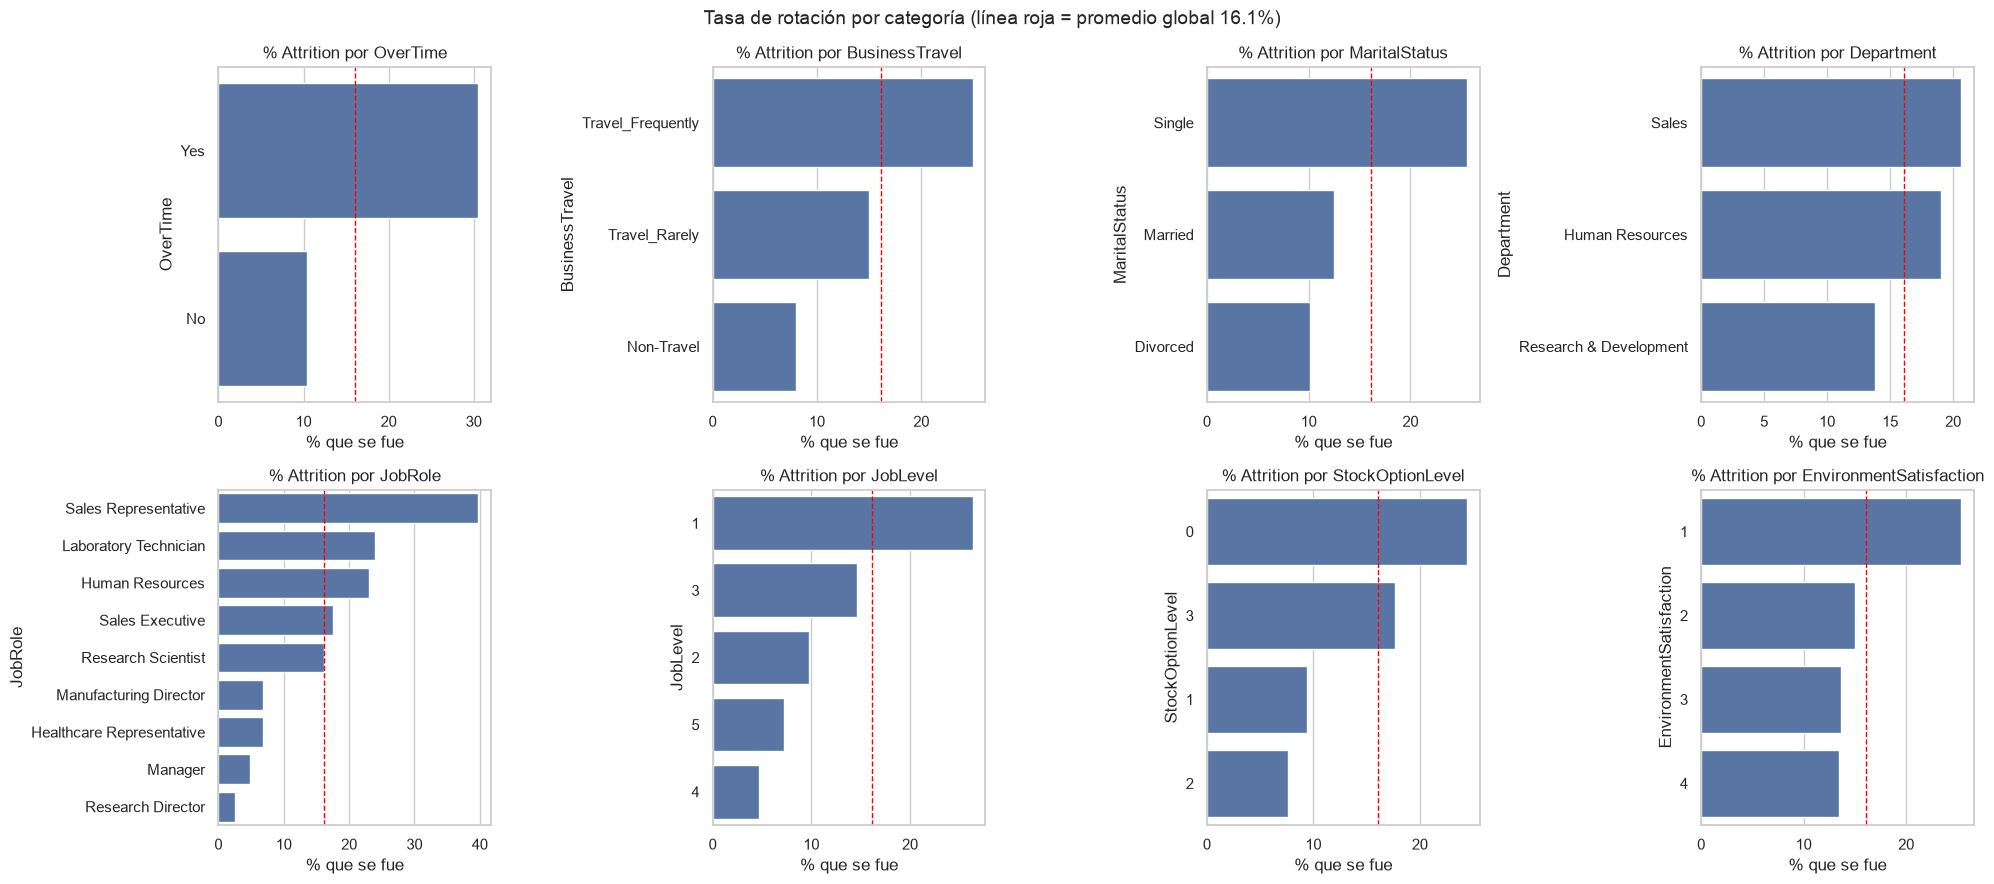

In [11]:
# Tasa de rotación (% de 'Yes') por categoría para las variables categóricas
cat_clave = ["OverTime", "BusinessTravel", "MaritalStatus", "Department",
             "JobRole", "JobLevel", "StockOptionLevel", "EnvironmentSatisfaction"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_clave):
    # Porcentaje de empleados que se fueron dentro de cada categoría
    tasa = (df_raw.groupby(col)["Attrition"]
            .apply(lambda s: (s == "Yes").mean() * 100)
            .sort_values(ascending=False))
    sns.barplot(x=tasa.values, y=tasa.index.astype(str), ax=ax, orient="h")
    ax.axvline(16.1, color="red", ls="--", lw=1)  # tasa global de referencia
    ax.set_title(f"% Attrition por {col}")
    ax.set_xlabel("% que se fue")
plt.suptitle("Tasa de rotación por categoría (línea roja = promedio global 16.1%)", fontsize=14)
plt.tight_layout()
plt.show()

**Hallazgos clave:**
- **Horas extra (`OverTime = Yes`)** es la señal más fuerte: la rotación se triplica (~31% contra ~10%).
- Los empleados **solteros**, los que **viajan frecuentemente** y los de **nivel 1 (`JobLevel`)** o **`StockOptionLevel = 0`** se van bastante más.
- Por rol, **Sales Representative** y **Laboratory Technician** tienen las tasas más altas.
- En los boxplots, quienes se van son **más jóvenes**, **ganan menos** y llevan **menos años** en la empresa.

### 2.5 Correlaciones entre variables numéricas

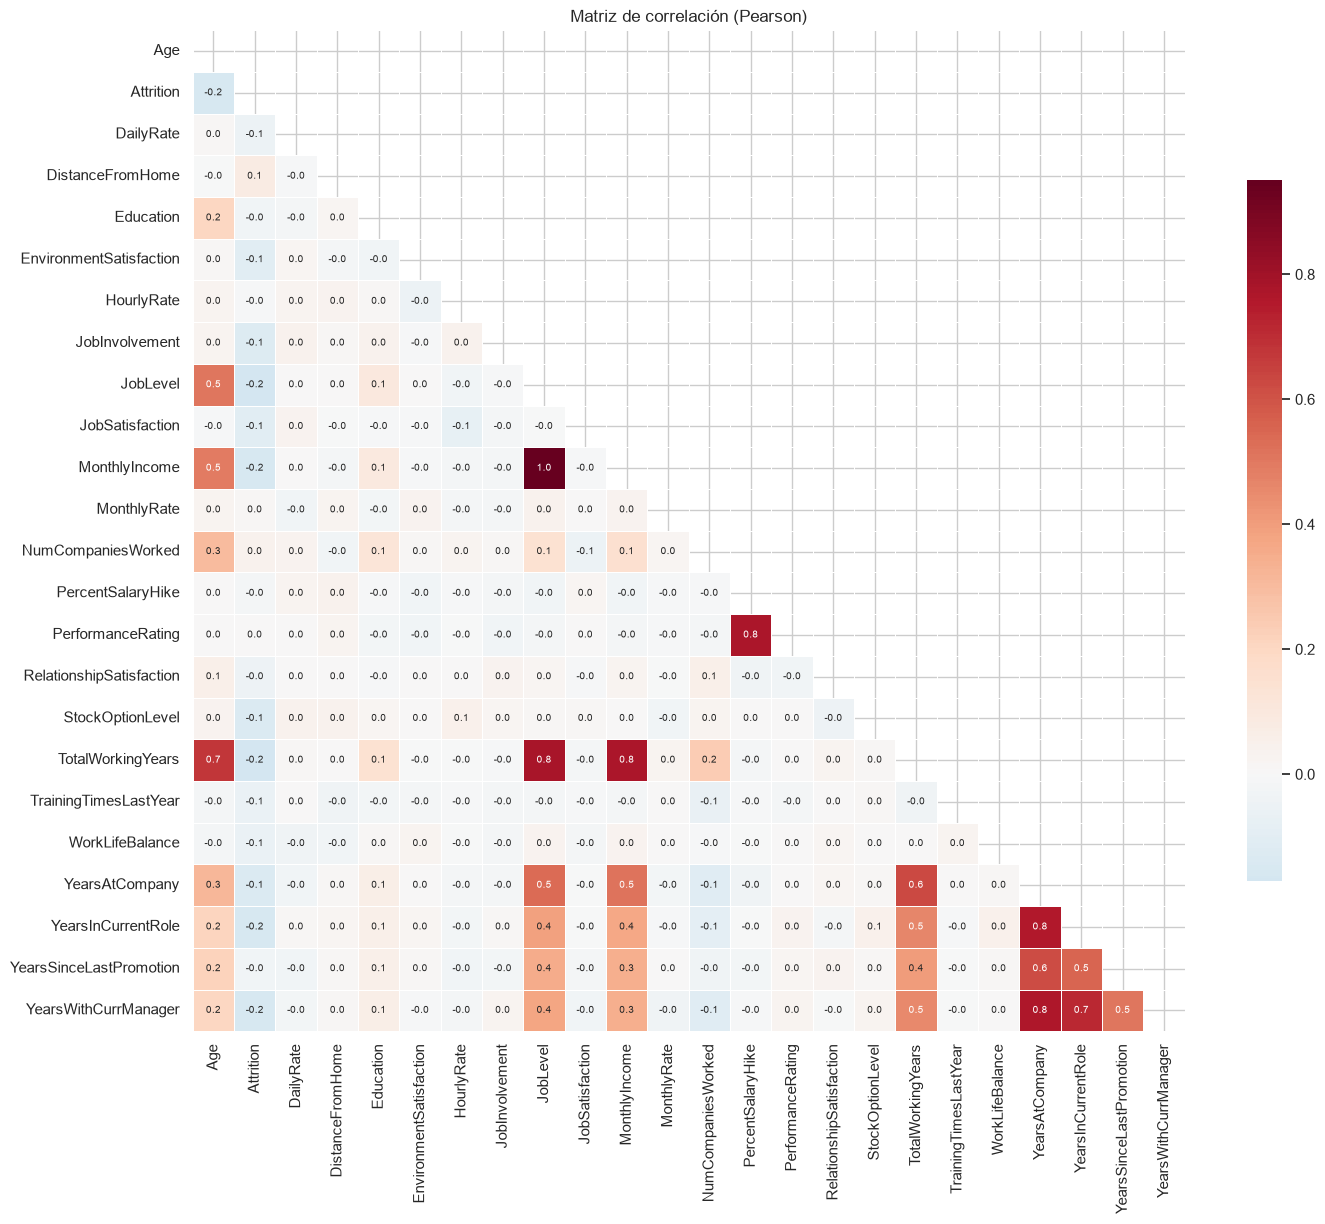

In [12]:
# Copia temporal con la variable objetivo en 0/1 para incluirla en la correlación
df_corr = df_raw.drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber"]).copy()
df_corr["Attrition"] = (df_corr["Attrition"] == "Yes").astype(int)

# Matriz de correlación de Pearson
corr = df_corr.select_dtypes("number").corr()

# Heatmap mostrando solo la mitad inferior (la matriz es simétrica)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(16, 13))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.7})
plt.title("Matriz de correlación (Pearson)")
plt.show()

In [13]:
# Correlación de cada variable numérica con Attrition, ordenada
corr["Attrition"].drop("Attrition").sort_values().to_frame("corr_con_attrition").round(3)

,corr_con_attrition
TotalWorkingYears,-0.171
JobLevel,-0.169
YearsInCurrentRole,-0.161
MonthlyIncome,-0.160
Age,-0.159
YearsWithCurrManager,-0.156
StockOptionLevel,-0.137
YearsAtCompany,-0.134
JobInvolvement,-0.130
JobSatisfaction,-0.103


**Hallazgos:**
- Hay **multicolinealidad** fuerte entre `JobLevel` y `MonthlyIncome` (~0.95), y entre `TotalWorkingYears`, `YearsAtCompany`, `YearsInCurrentRole` y `YearsWithCurrManager` (0.5–0.8). En un modelo lineal esto afecta la interpretación de los coeficientes, aunque no tanto la capacidad predictiva. Para el baseline se dejan todas las variables y se usa regularización L2 (la que trae `LogisticRegression` por defecto).
- Las correlaciones individuales con `Attrition` son débiles (|r| < 0.2). Las más negativas son `TotalWorkingYears`, `JobLevel`, `YearsInCurrentRole`, `MonthlyIncome` y `Age`, lo que confirma que el riesgo se concentra en perfiles jóvenes y junior.
- `DailyRate`, `HourlyRate` y `MonthlyRate` prácticamente no se relacionan con nada. Parecen ruido del dataset sintético.

## Paso 3. Limpieza de datos

Cada subsección revisa un tipo de problema, aplica una decisión y la justifica.

In [14]:
# Se trabaja sobre una copia para conservar los datos originales intactos
df = df_raw.copy()

# 3.1 Valores faltantes: conteo de nulos por columna
nulos = df.isna().sum()
print("Total de valores nulos:", nulos.sum())
print("Columnas con nulos:", nulos[nulos > 0].to_dict())

# Revisión adicional: cadenas vacías o espacios que pandas no detecta como NaN
vacios = (df.select_dtypes(exclude="number").apply(lambda s: s.str.strip() == "")).sum().sum()
print("Cadenas vacías:", vacios)

Total de valores nulos: 0
Columnas con nulos: {}
Cadenas vacías: 0


**Decisión 3.1 (faltantes):** no hay valores nulos ni cadenas vacías. **No se imputa nada.** Aun así, el pipeline del modelo se arma para recibir datos nuevos, que en producción sí podrían traer nulos (ver la reflexión final).

In [15]:
# 3.2 Duplicados: filas idénticas completas y IDs de empleado repetidos
print("Filas duplicadas:", df.duplicated().sum())
print("EmployeeNumber repetidos:", df["EmployeeNumber"].duplicated().sum())

# Duplicados sin contar el ID (dos empleados con exactamente el mismo perfil)
print("Duplicados ignorando el ID:", df.drop(columns="EmployeeNumber").duplicated().sum())

Filas duplicadas: 0
EmployeeNumber repetidos: 0
Duplicados ignorando el ID: 0


**Decisión 3.2 (duplicados):** no hay filas duplicadas, ni IDs repetidos, ni perfiles idénticos. **No se elimina ningún registro.**

In [16]:
# 3.3 Columnas sin información: constantes (un solo valor) e identificadores
constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Columnas constantes:", constantes)

# Se eliminan las constantes y el identificador del empleado
cols_a_eliminar = constantes + ["EmployeeNumber"]
df = df.drop(columns=cols_a_eliminar)
print("Columnas eliminadas:", cols_a_eliminar)
print("Nueva forma:", df.shape)

Columnas constantes: ['EmployeeCount', 'Over18', 'StandardHours']
Columnas eliminadas: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Nueva forma: (1470, 31)


**Decisión 3.3 (columnas irrelevantes):** se eliminan `EmployeeCount`, `Over18` y `StandardHours` porque tienen varianza cero y no pueden ayudar a distinguir clases. También se elimina `EmployeeNumber` porque es un ID: si el modelo lo usara, aprendería patrones espurios que no se generalizan a empleados nuevos.

In [17]:
# 3.4 Outliers: detección con el criterio IQR (fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR])
num_cols = df.select_dtypes("number").columns
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
es_outlier = (df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)

# Número y porcentaje de outliers por columna (solo las que tienen alguno)
resumen_out = pd.DataFrame({
    "n_outliers": es_outlier.sum(),
    "pct": (es_outlier.mean() * 100).round(1),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
}).query("n_outliers > 0").sort_values("n_outliers", ascending=False)
resumen_out

,n_outliers,pct,min,max
TrainingTimesLastYear,238,16.2,0,6
PerformanceRating,226,15.4,3,4
MonthlyIncome,114,7.8,1009,19999
YearsSinceLastPromotion,107,7.3,0,15
YearsAtCompany,104,7.1,0,40
StockOptionLevel,85,5.8,0,3
TotalWorkingYears,63,4.3,0,40
NumCompaniesWorked,52,3.5,0,9
YearsInCurrentRole,21,1.4,0,18
YearsWithCurrManager,14,1.0,0,17


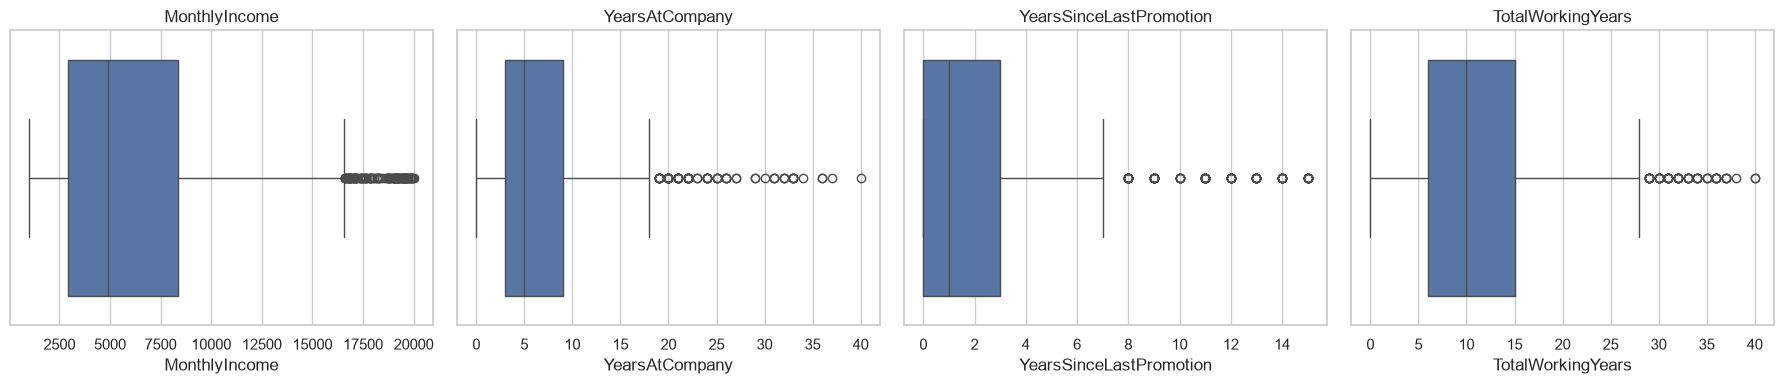

% Attrition entre outliers de MonthlyIncome: 4.4


In [18]:
# Visualización de las variables con más outliers
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["MonthlyIncome", "YearsAtCompany", "YearsSinceLastPromotion", "TotalWorkingYears"]):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# ¿Los outliers de ingreso se concentran en alguna clase? (proporción de Attrition entre ellos)
out_ingreso = es_outlier["MonthlyIncome"]
print("% Attrition entre outliers de MonthlyIncome:",
      round((df.loc[out_ingreso, "Attrition"] == "Yes").mean() * 100, 1))

**Decisión 3.4 (outliers): se conservan.**
- Son **valores plausibles**, no errores de captura: ingresos de ~19,000 corresponden a directores y gerentes (`JobLevel` 4–5), y 40 años de antigüedad es posible.
- En `PerformanceRating` y `TrainingTimesLastYear` el IQR marca "outliers" solo porque las variables son **discretas con pocos valores** (por ejemplo, `PerformanceRating` solo vale 3 o 4). No son anomalías.
- Eliminarlos quitaría información útil (los empleados senior casi no se van) y reduciría un dataset que ya es pequeño.
- Para que no dominen al modelo lineal, se usa **estandarización** (`StandardScaler`). En una iteración posterior se podría probar `log(MonthlyIncome)` o un `RobustScaler`.

In [19]:
# 3.5 Tipos de datos incorrectos

# a) Variable objetivo de texto ('Yes'/'No') a binaria (1/0)
df["Attrition"] = (df["Attrition"] == "Yes").astype(int)

# b) Variables de texto a tipo 'category' (más eficiente y explícito)
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
df[cat_cols] = df[cat_cols].astype("category")

# c) Variables ordinales codificadas como enteros: se verifica que estén en su rango válido
ordinales = {
    "Education": (1, 5), "EnvironmentSatisfaction": (1, 4), "JobInvolvement": (1, 4),
    "JobLevel": (1, 5), "JobSatisfaction": (1, 4), "PerformanceRating": (1, 4),
    "RelationshipSatisfaction": (1, 4), "StockOptionLevel": (0, 3), "WorkLifeBalance": (1, 4),
}
for col, (lo, hi) in ordinales.items():
    assert df[col].between(lo, hi).all(), f"{col} fuera de rango"
print("Todas las variables ordinales están dentro de su rango válido.")

# d) Revisión de valores negativos en variables que no deberían tenerlos
print("Valores negativos en columnas numéricas:", (df.select_dtypes("number") < 0).sum().sum())

df.dtypes.value_counts()

Todas las variables ordinales están dentro de su rango válido.
Valores negativos en columnas numéricas: 0


int64       24
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

**Decisión 3.5 (tipos):**
- `Attrition` pasa de texto a **binaria 0/1** para usarla como objetivo.
- Las 7 variables de texto (`BusinessTravel`, `Department`, `EducationField`, `Gender`, `JobRole`, `MaritalStatus`, `OverTime`) pasan a `category`. En el modelo se codifican con **One-Hot Encoding**.
- Las variables **ordinales** (`Education`, satisfacción, `JobLevel`, etc.) se dejan como **enteros** porque su orden tiene significado (4 = Very High > 1 = Low). Se validó que no hubiera valores fuera de rango ni negativos.

### Resumen de la limpieza

| Problema | Hallazgo | Decisión |
|---|---|---|
| Faltantes | 0 nulos | Ninguna acción |
| Duplicados | 0 filas | Ninguna acción |
| Columnas constantes / ID | 4 columnas | Eliminadas |
| Outliers (IQR) | Presentes, pero plausibles | Conservados y estandarizados |
| Tipos | Objetivo y categóricas como texto | Objetivo a 0/1, texto a `category`, ordinales validadas |

**Dataset limpio:** 1,470 registros × 31 columnas (30 predictoras + objetivo).

In [20]:
# Forma final y vista rápida del dataset limpio
print("Forma del dataset limpio:", df.shape)
df.head()

Forma del dataset limpio: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2


## Siguiente paso: entrenamiento con `train.py`

Las decisiones de limpieza de arriba están implementadas en la función `clean_data()` de `train.py`. Para entrenar y registrar una corrida en MLflow:

```bash
python train.py --C 0.1 --class-weight balanced --threshold 0.5 --seed 42
```
